# Projekt Z6 · Wpływ przygotowania danych na FFNN i SOM

## Pytanie badawcze

Jak sposób przygotowania danych i konfiguracji modelu wpływa na wyniki FFNN i SOM na podanych zbiorach danych?

## Dane
 - W zbiorze **Adult** przewidujemy, czy roczny dochód przekracza 50 tys. USD (klasa 1).
 - W **Banknote** rozróżniamy klasy 0 (prawdziwe) i 1 (podrobione) na podstawie cech obrazów banknotów.

[Adult w repozytorium UCI](https://archive.ics.uci.edu/dataset/2/adult) · [Banknote w repozytorium UCI](https://archive.ics.uci.edu/dataset/267/banknote+authentication)

## Opis kolumn zbioru Adult

| Kolumna | Rola | Typ | Braki | Opis |
| --- | --- | --- | --- | --- |
| `age` | cecha | całkowita | nie | wiek osoby |
| `workclass` | cecha | kategoria | tak | typ zatrudnienia: Private, Self-emp-not-inc, Self-emp-inc, Federal-gov, Local-gov, State-gov, Without-pay, Never-worked |
| `fnlwgt` | cecha | całkowita | nie | waga próbki (ile osób w populacji reprezentuje dany wiersz) |
| `education` | cecha | kategoria | nie | poziom wykształcenia (Bachelors, HS-grad, Masters, Doctorate itd.) |
| `education-num` | cecha | całkowita | nie | wykształcenie zapisane liczbowo (odpowiednik `education`) |
| `marital-status` | cecha | kategoria | nie | stan cywilny: Married-civ-spouse, Divorced, Never-married, Separated, Widowed itd. |
| `occupation` | cecha | kategoria | tak | zawód: Tech-support, Craft-repair, Sales, Exec-managerial, Prof-specialty itd. |
| `relationship` | cecha | kategoria | nie | rola w rodzinie: Wife, Husband, Own-child, Not-in-family, Unmarried, Other-relative |
| `race` | cecha | kategoria | nie | rasa: White, Black, Asian-Pac-Islander, Amer-Indian-Eskimo, Other |
| `sex` | cecha | binarna | nie | płeć: Female, Male |
| `capital-gain` | cecha | ciągła | nie | zyski kapitałowe |
| `capital-loss` | cecha | ciągła | nie | straty kapitałowe |
| `hours-per-week` | cecha | ciągła | nie | liczba przepracowanych godzin tygodniowo |
| `native-country` | cecha | kategoria | tak | kraj pochodzenia (United-States, Mexico, Philippines, Germany, India itd.) |
| `income` | target | binarna | nie | czy roczny dochód przekracza 50 tys. USD: `>50K` lub `<=50K` |

## Opis kolumn Banknotes

| Kolumna | Rola | Typ | Opis |
| --- | --- | --- | --- |
| `variance` | cecha | ciągła | wariancja obrazu |
| `skewness` | cecha | ciągła | skośność obrazu |
| `curtosis` | cecha | ciągła | kurtoza obrazu |
| `entropy` | cecha | ciągła | entropia obrazu |
| `class` | target | całkowita | autentyczność banknotu: `0` = prawdziwy, `1` = podrobiony |

In [19]:
%pip install -q "minisom" "ucimlrepo" "tensorflow" "scikit-learn" "seaborn" "keras"


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [20]:
from importlib.metadata import version
from pathlib import Path
import platform

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from IPython.display import Markdown, display
from minisom import MiniSom
from scipy.spatial.distance import cdist
from sklearn.compose import ColumnTransformer
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, StandardScaler
from tensorflow import keras
from ucimlrepo import fetch_ucirepo

SEED = 42
HOLDOUT_SHARE = 0.30
TEST_SHARE_OF_HOLDOUT = 0.50

FFNN = dict(
    hidden_units=(32, 16), hidden_activation='relu', output_activation='sigmoid',
    optimizer=keras.optimizers.Adam, loss='binary_crossentropy', learning_rate=0.001,
    max_epochs=100, batch_size=64, monitor='val_loss', patience=10, threshold=0.5,
)

SOM = dict(
    sigma_min=1, sigma_divisor=4,
    updates=10_000, distance_batch_size=1024,

    # heurystyka: liczba_neuronów = neurons_factor*sqrt(rozmiar_datasetu)
    neurons_factor=5,

    # domyślne ustawienia biblioteki MiniSOM
    learning_rate=0.5,
    topology='rectangular', activation_distance='euclidean',
    neighborhood_function='gaussian', decay_function='asymptotic_decay',
    sigma_decay_function='asymptotic_decay',
)

SCALERS = {'StandardScaler': StandardScaler, 'MinMaxScaler': MinMaxScaler}
ADULT_VARIANTS = {
    'A1': ('A', 'StandardScaler'), 'A2': ('A', 'MinMaxScaler'),
    'B1': ('B', 'StandardScaler'), 'B2': ('B', 'MinMaxScaler'),
    'C1': ('C', 'StandardScaler'), 'C2': ('C', 'MinMaxScaler'),
}
BANK_VARIANTS = {'N1': ('N', 'StandardScaler'), 'N2': ('N', 'MinMaxScaler')}
ADULT_VARIANTS['A1-L1'] = ADULT_VARIANTS['A1']
ADULT_VARIANTS['A1-64x32'] = ADULT_VARIANTS['A1']
ADULT_VARIANTS['A1-Leaky'] = ADULT_VARIANTS['A1']
BANK_VARIANTS['N1-L1'] = BANK_VARIANTS['N1']
BANK_VARIANTS['N1-2'] = BANK_VARIANTS['N1']
SOM_ONLY_VARIANTS = {'A1-L1': 'manhattan', 'N1-L1': 'manhattan'}
FFNN_VARIANT_CONFIGS = {
    'A1-64x32': dict(hidden_units=(64, 32)),
    'A1-Leaky': dict(negative_slope=0.01),
    'N1': dict(hidden_units=(8,)), 'N2': dict(hidden_units=(8,)),
    'N1-2': dict(hidden_units=(2,)),
}
FFNN_ONLY_VARIANTS = {'A1-64x32', 'A1-Leaky', 'N1-2'}
CDIST_METRICS = {'euclidean': 'euclidean', 'manhattan': 'cityblock'}
MISSING_CATEGORY = 'BRAK_DANYCH'

sns.set_theme(style='whitegrid')
libraries = (
    'pandas', 'numpy', 'matplotlib', 'seaborn', 'scipy', 'scikit-learn',
    'tensorflow', 'keras', 'minisom', 'ucimlrepo',
)


In [21]:
ADULT_COLUMNS = (
    'age workclass fnlwgt education education-num marital-status occupation '
    'relationship race sex capital-gain capital-loss hours-per-week native-country'
).split()
ADULT_NUMERIC = 'age fnlwgt education-num capital-gain capital-loss hours-per-week'.split()
BANK_NUMERIC = ['variance', 'skewness', 'curtosis', 'entropy']


def load_adult():
    files = [Path('adult.data'), Path('adult.test')]
    if all(path.is_file() for path in files):
        options = dict(names=[*ADULT_COLUMNS, 'class'], skipinitialspace=True, comment='|')
        raw = pd.concat([pd.read_csv(path, **options) for path in files], ignore_index=True)
        X, target = raw[ADULT_COLUMNS].copy(), raw['class']
        source = 'lokalne pliki UCI'
    else:
        data = fetch_ucirepo(id=2).data
        X, target = data.features.copy(), data.targets.iloc[:, 0]
        X = X[ADULT_COLUMNS]
        source = 'ucimlrepo (UCI 2)'

    for name in X.columns.difference(ADULT_NUMERIC):
        column = X[name].astype(object)
        X[name] = column.str.strip().replace('?', np.nan).astype(object)
        X[name] = X[name].where(X[name].notna(), np.nan)
    X[ADULT_NUMERIC] = X[ADULT_NUMERIC].replace(r'^\s*\?\s*$', np.nan, regex=True)
    X[ADULT_NUMERIC] = X[ADULT_NUMERIC].apply(pd.to_numeric)
    y = target.str.strip().str.rstrip('.').map({'<=50K': 0, '>50K': 1})
    return X, y, source


def load_banknote():
    path = Path('data_banknote_authentication.txt')
    if path.is_file():
        raw = pd.read_csv(path, names=[*BANK_NUMERIC, 'class'])
        return raw[BANK_NUMERIC], raw['class'], 'lokalny plik UCI'
    data = fetch_ucirepo(id=267).data
    return data.features[BANK_NUMERIC], data.targets.iloc[:, 0], 'ucimlrepo (UCI 267)'


def inspect_and_split(x, y, source):
    if not y.isin([0, 1]).all():
        raise ValueError('Oczekiwano etykiet 0 i 1 dla wszystkich rekordów.')
    y = y.astype('int64').rename('class')
    raw = x.assign(class_=y).rename(columns={'class_': 'class'})
    clean = raw.drop_duplicates()
    x, y = clean.drop(columns='class'), clean['class']
    missing = int(x.isna().any(axis=1).sum())
    summary = {
        'Źródło': source,
        'Rekordy źródłowe': len(raw),
        'Duplikaty': len(raw) - len(clean),
        'Rekordy z brakami po czyszczeniu': missing,
        'Z brakami (%)': round(100 * missing / len(clean), 2),
        'Klasa 0 po czyszczeniu': int(y.eq(0).sum()),
        'Klasa 1 po czyszczeniu': int(y.eq(1).sum()),
    }

    x_train, x_holdout = train_test_split(
        x, test_size=HOLDOUT_SHARE, stratify=y, random_state=SEED,
    )
    x_val, x_test = train_test_split(
        x_holdout, test_size=TEST_SHARE_OF_HOLDOUT, stratify=y.loc[x_holdout.index],
        random_state=SEED,
    )
    return summary, y, (x_train, x_val, x_test), clean


adult_summary, adult_y, adult_splits, adult_data = inspect_and_split(*load_adult())
bank_summary, bank_y, bank_splits, bank_data = inspect_and_split(*load_banknote())

### Przykładowe rekordy

Pokazujemy po pięć wierszy po usunięciu duplikatów. W Adult klasa 0 oznacza dochód do 50 tys. USD, a klasa 1 dochód powyżej tej kwoty. W Banknote używamy kodów 0 (prawdziwy) i 1 (podrobiony).

In [22]:
for name, frame in [('Adult', adult_data), ('Banknote', bank_data)]:
    display(Markdown(f'**{name}**'))
    display(frame.head().rename(columns={'class': 'Klasa'}).replace({np.nan: 'Brak danych'}))

display(Markdown('**Podsumowanie zbiorów**'))
display(pd.DataFrame.from_dict({'Adult': adult_summary, 'Banknote': bank_summary},
                               orient='index').rename_axis('Zbiór'))

**Adult**

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,Klasa
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,0
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,0
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,0
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,0
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,0


**Banknote**

,variance,skewness,curtosis,entropy,Klasa
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


**Podsumowanie zbiorów**

,Źródło,Rekordy źródłowe,Duplikaty,Rekordy z brakami po czyszczeniu,Z brakami (%),Klasa 0 po czyszczeniu,Klasa 1 po czyszczeniu
Zbiór,,,,,,,
Adult,lokalne pliki UCI,48842,52,3615,7.41,37109,11681
Banknote,lokalny plik UCI,1372,24,0,0.00,738,610


### Rozkłady cech

Histogramy pokazują oryginalne wartości przed skalowaniem. Dla capital-gain i capital-loss oś liczebności jest logarytmiczna, żeby uwidocznić rzadkie wartości. Na wykresach Adult braki mają osobny słupek. Gdy cecha ma ponad 10 kategorii, pokazujemy osiem najczęstszych i łączymy resztę w „Pozostałe”.

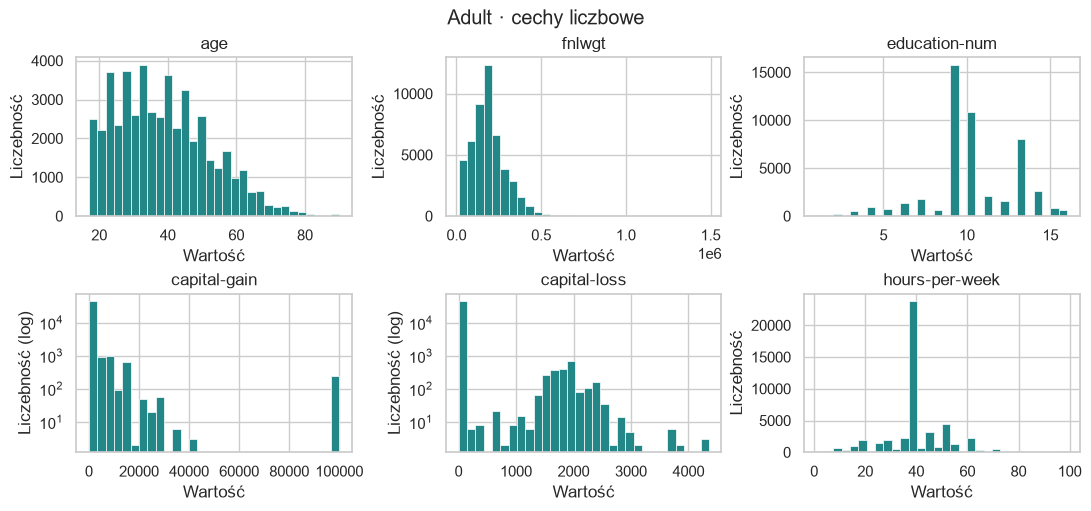

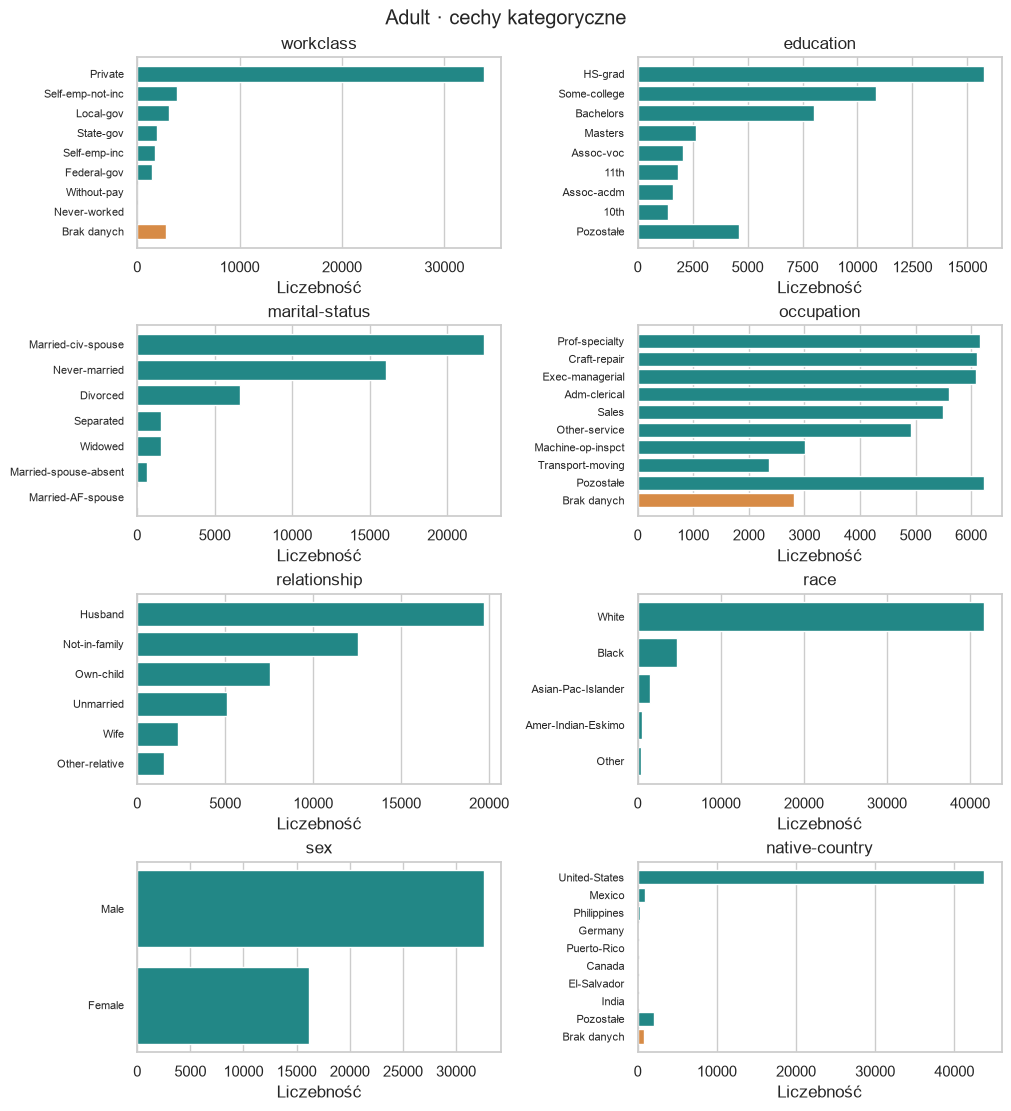

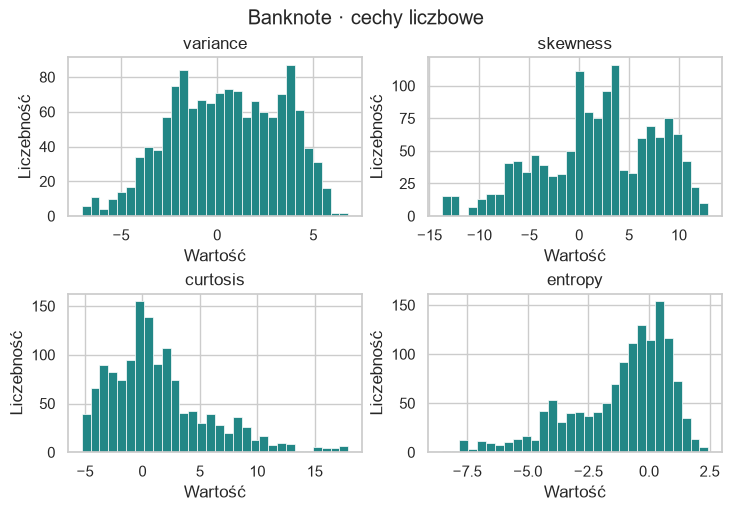

In [23]:
def plot_histograms(frame, columns, title, ncols):
    fig, axes = plt.subplots(2, ncols, figsize=(3.6 * ncols, 5), layout='constrained')
    for ax, column in zip(axes.flat, columns):
        use_log_counts = column in ('capital-gain', 'capital-loss')
        ax.hist(frame[column].dropna(), bins=30, color='#228786',
                edgecolor='white', linewidth=.5, log=use_log_counts)
        ylabel = 'Liczebność (log)' if use_log_counts else 'Liczebność'
        ax.set(title=column, xlabel='Wartość', ylabel=ylabel)
    fig.suptitle(title)
    plt.show()


plot_histograms(adult_data, ADULT_NUMERIC, 'Adult · cechy liczbowe', ncols=3)

categorical = [column for column in ADULT_COLUMNS if column not in ADULT_NUMERIC]
fig, axes = plt.subplots(4, 2, figsize=(10, 11), layout='constrained')
for ax, column in zip(axes.flat, categorical):
    counts = adult_data[column].value_counts()
    if len(counts) > 10:
        counts = pd.concat([counts.iloc[:8], pd.Series({'Pozostałe': counts.iloc[8:].sum()})])
    missing = adult_data[column].isna().sum()
    if missing:
        counts.loc['Brak danych'] = missing
    colors = ['#d78b46' if category == 'Brak danych' else '#228786' for category in counts.index]
    ax.barh(counts.index, counts.to_numpy(), color=colors)
    ax.invert_yaxis()
    ax.set(title=column, xlabel='Liczebność')
    ax.tick_params(axis='y', labelsize=8)
    ax.grid(axis='y', visible=False)
fig.suptitle('Adult · cechy kategoryczne')
plt.show()


plot_histograms(bank_data, BANK_NUMERIC, 'Banknote · cechy liczbowe', ncols=2)


## Metoda

Dla każdego zbioru stosujemy jeden stratyfikowany podział 70/15/15 na trening, walidację i test. W Adult walidację i test ograniczamy do wspólnych kompletnych rekordów. W Banknote wykorzystujemy całą walidację i test. _Imputację_, skalowanie cech liczbowych i _kodowanie one-hot_ kategorii dopasowujemy wyłącznie na treningu.

### Wyjaśnienie

- **Imputacja** to uzupełnianie brakujących wartości. W Adult warianty **A** wstawiają medianę dla cech liczbowych i najczęstszą wartość dla kategorycznych. Wariant **C** używa mediany oraz wskaźnika braku dla liczb i wartości `BRAK_DANYCH` dla kategorii. Wariant **B** usuwa niekompletne rekordy treningowe. Banknote nie zawiera braków.
- **One-hot encoding** zamienia kategorię, np. `education`, na osobne kolumny 0/1 dla jej wartości. Dzięki temu model nie interpretuje kategorii jako liczb o sztucznej kolejności.

### Warianty przygotowania danych

| Zbiór | Wariant | Braki | Skalowanie |
| --- | --- | --- | --- |
| Adult | A1 | Mediana dla liczb, najczęstsza wartość dla kategorii | Standaryzacja |
| Adult | A2 | Jak w A1 | Min–Max |
| Adult | B1 | Usunięcie niekompletnych rekordów treningowych | Standaryzacja |
| Adult | B2 | Jak w B1 | Min–Max |
| Adult | C1 | `BRAK_DANYCH` dla kategorii; mediana i wskaźnik braku dla liczb z brakami | Standaryzacja |
| Adult | C2 | Jak w C1 | Min–Max |
| Banknote | N1 | Dane kompletne | Standaryzacja |
| Banknote | N2 | Jak w N1 | Min–Max |

### Dodatkowe porównania modeli

| Wariant | Model | Zmiana względem bazowego |
| --- | --- | --- |
| A1-L1 | SOM | Odległość Manhattan (L1); przygotowanie danych jak w A1 |
| N1-L1 | SOM | Odległość Manhattan (L1); przygotowanie danych jak w N1 |
| A1-64x32 | FFNN | Warstwy ukryte: 64 i 32 neurony zamiast 32 i 16; przygotowanie danych jak w A1 |
| A1-Leaky | FFNN | LeakyReLU (nachylenie 0,01) zamiast ReLU; przygotowanie danych jak w A1 |
| N1-2 | FFNN | 2 neurony w jednej warstwie zamiast 8; przygotowanie danych jak w N1 |

### FFNN

- **Architektura bazowa:** Adult ma dwie warstwy ReLU (32 i 16 neuronów), a Banknote jedną warstwę ReLU z 8 neuronami. W obu modelach wyjście sigmoid i optymalizator Adam.
- **Trening:** maksymalnie 100 epok, wczesne zatrzymanie na podstawie straty walidacyjnej.
- **Krzywe loss:** binary cross-entropy zapisujemy po każdej epoce dla treningu i walidacji.
- **A1-64x32:** podwajamy szerokość obu warstw, zachowując przygotowanie danych z A1.
- **A1-Leaky:** warstwy ukryte mają 32 i 16 neuronów oraz aktywację LeakyReLU, która dla wartości ujemnych ma małe nachylenie.
- **N1-2 (Banknote):** zmniejszamy warstwę ukrytą z 8 do 2 neuronów, zachowując preprocessing N1.

### SOM

- **Rozmiar siatki:** szacujemy liczbę neuronów jako `5 × sqrt(n_train)`, gdzie `n_train` to liczba próbek treningowych przed zastosowaniem strategii obsługi braków. Bok kwadratowej siatki wynosi więc `s = round(sqrt(5 × sqrt(n_train)))`. Rozmiar ustalamy raz na zbiór i zachowujemy we wszystkich wariantach.
- **Uczenie:** każdą mapę trenujemy przez 10 000 aktualizacji.
- **Sigma:** parametr funkcji sąsiedztwa Gaussa. Określa, jak szeroki obszar wokół zwycięskiego neuronu jest aktualizowany - większa sigma obejmuje więcej neuronów. Początkowo ustawiamy `sigma = max(1, s / 4)`, gdzie `s` to bok mapy; następnie sigma maleje asymptotycznie podczas uczenia. Daje to sigma 7,5 dla mapy Adult 30x30 i 3 dla Banknote 12x12.
- **Krzywe SOM:** ponieważ SOM jest nienadzorowany, pokazujemy błąd kwantyzacji (QE), a nie stratę klasyfikacyjną. Liczymy go dla treningu i walidacji na starcie oraz co 2 000 aktualizacji, używając metryki danej mapy.
- **Wybór neuronu:** domyślnie używamy odległości euklidesowej (L2). W wariantach A1-L1 i N1-L1 używamy odległości Manhattan (L1), przy tym samym przygotowaniu danych i rozmiarze mapy co odpowiednio w A1 i N1.
- **Błąd topograficzny:** odsetek próbek, dla których dwa najbliższe neurony nie sąsiadują na mapie.

Skalery i strategie braków porównujemy przy tych samych ustawieniach modeli i jednym ziarnie **42** dla podziału oraz treningu.

In [24]:
def build_preprocessor(x_train, numeric, strategy, scaler):
    categorical = [name for name in x_train.columns if name not in numeric]
    numeric_steps = []
    if strategy in ('A', 'C'):
        numeric_steps.append(('imputer', SimpleImputer(strategy='median')))
    numeric_steps.append(('scaler', SCALERS[scaler]()))
    branches = [('numeric', Pipeline(numeric_steps), numeric)]

    if categorical:
        category_steps = []
        if strategy == 'A':
            category_steps.append(('imputer', SimpleImputer(strategy='most_frequent')))
        if strategy == 'C':
            category_steps.append(('imputer', SimpleImputer(strategy='constant',
                                                              fill_value=MISSING_CATEGORY)))
        category_steps.append(('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)))
        branches.append(('categorical', Pipeline(category_steps), categorical))
    if strategy == 'C':
        missing_numeric = x_train[numeric].columns[x_train[numeric].isna().any()].tolist()
        if missing_numeric:
            branches.append(('missing', MissingIndicator(features='all'), missing_numeric))
    return ColumnTransformer(branches)


def prepare_variant(splits, y, numeric, strategy, scaler):
    x_train, x_val, x_test = splits
    if strategy == 'B':
        x_train = x_train.dropna()

    preprocessor = build_preprocessor(x_train, numeric, strategy, scaler).fit(x_train)
    feature_count = len(preprocessor.get_feature_names_out())

    def transform(part):
        values = np.asarray(preprocessor.transform(part), dtype=np.float32)
        if values.shape != (len(part), feature_count) or not np.isfinite(values).all():
            raise ValueError('Nieprawidłowy kształt lub braki po preprocessingu.')
        return values, y.loc[part.index].to_numpy()

    return transform(x_train), transform(x_val), transform(x_test)

In [25]:
def fit_ffnn(train, val, seed, *, hidden_units=None, negative_slope=None):
    x_train, _ = train
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)

    if hidden_units is None:
        hidden_units = FFNN['hidden_units']
    hidden_layers = []
    for units in hidden_units:
        activation = FFNN['hidden_activation']
        if negative_slope is not None:
            activation = keras.layers.LeakyReLU(negative_slope=negative_slope)
        hidden_layers.append(keras.layers.Dense(units, activation=activation))
    model = keras.Sequential([
        keras.Input(shape=(x_train.shape[1],)),
        *hidden_layers,
        keras.layers.Dense(1, activation=FFNN['output_activation']),
    ])
    model.compile(
        optimizer=FFNN['optimizer'](learning_rate=FFNN['learning_rate']),
        loss=FFNN['loss'], steps_per_execution=16,
    )
    options = tf.data.Options()
    options.threading.private_threadpool_size = 2
    training = tf.data.Dataset.from_tensor_slices(train)
    training = training.shuffle(len(x_train), seed=seed).batch(FFNN['batch_size'])
    validation = tf.data.Dataset.from_tensor_slices(val).batch(FFNN['batch_size'])
    early_stop = keras.callbacks.EarlyStopping(
        monitor=FFNN['monitor'], patience=FFNN['patience'], restore_best_weights=True,
    )
    history = model.fit(
        training.with_options(options), validation_data=validation.with_options(options),
        epochs=FFNN['max_epochs'], callbacks=[early_stop], shuffle=False, verbose=0,
    )
    return model, history.history


def closest_neurons(samples, weights, activation_distance, *, find_two=False):
    metric = CDIST_METRICS[activation_distance]
    winners, runners_up = [], []
    size = SOM['distance_batch_size']
    for start in range(0, len(samples), size):
        distances = cdist(samples[start:start + size], weights, metric=metric)
        best = distances.argmin(axis=1)
        winners.append(best)
        if find_two:
            distances[np.arange(len(best)), best] = np.inf
            runners_up.append(distances.argmin(axis=1))
    return np.concatenate(winners), np.concatenate(runners_up) if find_two else None


def quantization_error(samples, weights, activation_distance):
    winners, _ = closest_neurons(samples, weights, activation_distance)
    norm_order = 1 if activation_distance == 'manhattan' else 2
    return np.linalg.norm(samples - weights[winners], ord=norm_order, axis=1).mean()


def fit_som(x_train, x_val, side, seed, activation_distance):
    som = MiniSom(
        side, side, x_train.shape[1], random_seed=seed,
        sigma=max(SOM['sigma_min'], side / SOM['sigma_divisor']),
        learning_rate=SOM['learning_rate'], topology=SOM['topology'],
        activation_distance=activation_distance,
        neighborhood_function=SOM['neighborhood_function'],
        decay_function=SOM['decay_function'], sigma_decay_function=SOM['sigma_decay_function'],
    )
    som.random_weights_init(x_train)
    curve = {'steps': [], 'train': [], 'val': []}

    def record_quantization_error(step):
        weights = som.get_weights().reshape(side * side, -1)
        curve['steps'].append(step)
        curve['train'].append(quantization_error(x_train, weights, activation_distance))
        curve['val'].append(quantization_error(x_val, weights, activation_distance))

    record_quantization_error(0)
    curve_interval = max(1, SOM['updates'] // 5)
    rng = np.random.default_rng(seed)
    for step, index in enumerate(rng.integers(len(x_train), size=SOM['updates'])):
        sample = x_train[index]
        som.update(sample, som.winner(sample), step, SOM['updates'])
        completed = step + 1
        if completed % curve_interval == 0 or completed == SOM['updates']:
            record_quantization_error(completed)
    return som, curve


def label_som(x_train, y_train, weights, activation_distance):
    winners, _ = closest_neurons(x_train, weights, activation_distance)
    votes = np.zeros((len(weights), 2), dtype=int)
    np.add.at(votes, (winners, y_train), 1)
    overall_majority = np.bincount(y_train, minlength=2).argmax()
    labels = np.where(votes[:, 0] == votes[:, 1], overall_majority, votes.argmax(axis=1))
    occupied = votes.sum(axis=1) > 0
    assigned = np.flatnonzero(occupied)
    nearest_assigned = cdist(weights[~occupied], weights[assigned], metric='euclidean').argmin(axis=1)
    labels[~occupied] = labels[assigned[nearest_assigned]]
    return labels


def evaluate_som(x, weights, labels, side, activation_distance):
    winner, runner_up = closest_neurons(x, weights, activation_distance, find_two=True)
    row_gap = winner // side - runner_up // side
    col_gap = winner % side - runner_up % side
    nonadjacent = row_gap**2 + col_gap**2 > 2
    norm_order = 1 if activation_distance == 'manhattan' else 2
    qe = np.linalg.norm(x - weights[winner], ord=norm_order, axis=1).mean()
    return labels[winner], qe, nonadjacent.mean()

## Wyniki

Podajemy wyniki pojedynczego treningu każdego modelu w każdym wariancie. Macro-recall i macro-F1 to średnie wartości odpowiednio recall i F1 dla obu klas. F1 klasy >50K pokazuje skuteczność rozpoznawania wyższych dochodów w Adult. Metryki klasyfikacji i błąd topograficzny (TE) są w skali od 0 do 1.

Błąd kwantyzacji (QE) to średnia odległość rekordu testowego od jego najlepiej dopasowanego neuronu. Do obliczenia QE stosujemy tę samą metrykę co przy dopasowaniu neuronu (L1 albo L2). Bezpośrednie porównanie QE ma sens przy tej samej metryce i reprezentacji danych.

Na mapie klas kolor oznacza etykietę przypisaną neuronowi na podstawie danych treningowych. Neurony bez trafień przejmują etykietę najbliższego oznaczonego neuronu. Jasne obszary U-matrix wskazują duże względne różnice między sąsiadującymi neuronami. U-matrix we wszystkich wariantach używa odległości euklidesowej między wagami neuronów.

In [26]:
def classification_scores(y, predicted):
    report = classification_report(
        y, predicted, labels=[0, 1], output_dict=True, zero_division=0,
    )
    return {
        'Accuracy': report['accuracy'],
        'Macro-recall': report['macro avg']['recall'],
        'Macro-F1': report['macro avg']['f1-score'],
        'F1 klasy >50K': report['1']['f1-score'],
    }


def run_experiment(splits, y, numeric, variants, *, complete_evaluation=False):
    x_train, x_val, x_test = splits
    if complete_evaluation:
        x_val, x_test = x_val.dropna(), x_test.dropna()
    side = round(np.sqrt(SOM['neurons_factor'] * np.sqrt(len(x_train))))
    records, maps, matrices, loss_histories = [], {}, {}, {}
    for variant, (strategy, scaler) in variants.items():
        train, val, test = prepare_variant((x_train, x_val, x_test), y, numeric, strategy, scaler)
        train_x, train_y = train
        test_x, test_y = test
        common = {'Wariant': variant, 'Trening': len(train_y), 'Test': len(test_y)}
        if variant not in SOM_ONLY_VARIANTS:
            model, history = fit_ffnn(train, val, SEED, **FFNN_VARIANT_CONFIGS.get(variant, {}))
            loss_histories[(variant, 'FFNN')] = {
                'steps': list(range(1, len(history['loss']) + 1)),
                'train': history['loss'], 'val': history['val_loss'],
            }
            probability = model(test_x, training=False).numpy().ravel()
            predicted = (probability >= FFNN['threshold']).astype(int)
            matrices[(variant, 'FFNN')] = confusion_matrix(test_y, predicted, labels=[0, 1])
            records.append({**common, 'Model': 'FFNN', **classification_scores(test_y, predicted)})

        if variant in FFNN_ONLY_VARIANTS:
            continue

        activation_distance = SOM_ONLY_VARIANTS.get(variant, SOM['activation_distance'])
        som, som_history = fit_som(train_x, val[0], side, SEED, activation_distance)
        loss_histories[(variant, 'SOM')] = som_history
        weights = som.get_weights().reshape(side * side, -1)
        labels = label_som(train_x, train_y, weights, activation_distance)
        predicted, qe, te = evaluate_som(test_x, weights, labels, side, activation_distance)
        matrices[(variant, 'SOM')] = confusion_matrix(test_y, predicted, labels=[0, 1])
        records.append({**common, 'Model': 'SOM', **classification_scores(test_y, predicted),
                        'Błąd kwantyzacji (QE)': qe, 'Błąd topograficzny': te})
        maps[variant] = {
            'U-matrix': som.distance_map(scaling='mean'),
            'Klasy neuronów': labels.reshape(side, side),
        }
    return pd.DataFrame(records).set_index(['Wariant', 'Model']), maps, matrices, loss_histories


def plot_confusion_matrices(matrices, labels, dataset):
    ncols = 4
    nrows = (len(matrices) + ncols - 1) // ncols
    vmax = max(matrix.max() for matrix in matrices.values())
    fig, axes = plt.subplots(nrows, ncols, figsize=(10, 2.35 * nrows),
                             squeeze=False, layout='constrained')
    for index, ((variant, model), matrix) in enumerate(matrices.items()):
        row, col = divmod(index, ncols)
        ax = axes[row, col]
        ConfusionMatrixDisplay(matrix, display_labels=labels).plot(
            ax=ax, cmap='Blues', colorbar=False, values_format='d',
            im_kw={'vmin': 0, 'vmax': vmax},
        )
        ax.grid(False)
        ax.set(title=f'{variant} · {model}',
               xlabel='Przewidziana' if row == nrows - 1 else '',
               ylabel='Rzeczywista' if col == 0 else '')
    for ax in list(axes.flat)[len(matrices):]:
        ax.set_visible(False)
    fig.suptitle(f'{dataset} · macierze pomyłek')
    plt.show()


def plot_macro_f1(results, dataset):
    fig, ax = plt.subplots(figsize=(7.5, 3.2), layout='constrained')
    sns.barplot(data=results.reset_index(), x='Wariant', y='Macro-F1',
                hue='Model', palette=['#228786', '#d78b46'], errorbar=None, ax=ax)
    for bars in ax.containers:
        ax.bar_label(bars, fmt='%.4f', padding=3, fontsize=9)
    ax.set(ylim=(0, 1.1), yticks=np.linspace(0, 1, 6),
           title=f'{dataset} · Macro-F1 na teście')
    ax.legend(title=None, loc='lower right')
    plt.show()


def plot_loss_curves(loss_histories, dataset, model):
    curves = [(variant, history) for (variant, kind), history in loss_histories.items()
              if kind == model]
    if not curves:
        return

    ncols = 2
    nrows = (len(curves) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(10, 2.7 * nrows),
                             squeeze=False, layout='constrained')
    x_label = 'Epoka' if model == 'FFNN' else 'Aktualizacje SOM'
    y_label = 'Binary cross-entropy' if model == 'FFNN' else 'Błąd kwantyzacji (QE)'
    for ax, (variant, history) in zip(axes.flat, curves):
        ax.plot(history['steps'], history['train'], label='Trening')
        ax.plot(history['steps'], history['val'], label='Walidacja', linestyle='--')
        ax.set(title=variant, xlabel=x_label, ylabel=y_label)
        ax.grid(axis='y', alpha=.25)
        ax.legend(fontsize=8)
    for ax in list(axes.flat)[len(curves):]:
        ax.set_visible(False)
    title = (f'{dataset} · FFNN · loss' if model == 'FFNN'
             else f'{dataset} · SOM · QE')
    fig.suptitle(title)
    plt.show()


def plot_som_maps(maps, variants, dataset, class_labels):
    nrows = (len(maps) + 1) // 2
    class_colors = ListedColormap(['#366ca0', '#e39a4c'])
    styles = {
        'U-matrix': dict(cmap='viridis', vmin=0, vmax=1),
        'Klasy neuronów': dict(cmap=class_colors, vmin=-.5, vmax=1.5),
    }
    for kind, style in styles.items():
        fig, axes = plt.subplots(nrows, 2, figsize=(6.4, 3 * nrows),
                                 squeeze=False, layout='constrained')
        for ax, (variant, panels) in zip(axes.flat, maps.items()):
            heat = ax.imshow(panels[kind], interpolation='nearest', **style)
            ax.set(title=f'{variant} · {variants[variant][1]}', xticks=[], yticks=[])
        for ax in list(axes.flat)[len(maps):]:
            ax.set_visible(False)
        colorbar = fig.colorbar(heat, ax=axes, shrink=.8)
        if kind == 'Klasy neuronów':
            colorbar.set_ticks([0, 1], labels=class_labels)
        else:
            colorbar.set_label('Względna odległość L2')
        fig.suptitle(f'{dataset} · SOM · {kind}')
        plt.show()

### Adult

In [27]:
adult_results, adult_maps, adult_matrices, adult_loss_histories = run_experiment(
    adult_splits, adult_y, ADULT_NUMERIC, ADULT_VARIANTS, complete_evaluation=True,
)

Trening  Test  Accuracy  Macro-recall  Macro-F1  \
Wariant  Model                                                    
A1       FFNN     34153  6749    0.8543        0.7745    0.7917   
         SOM      34153  6749    0.8218        0.7106    0.7321   
A2       FFNN     34153  6749    0.8514        0.7729    0.7886   
         SOM      34153  6749    0.8225        0.7123    0.7337   
B1       FFNN     31639  6749    0.8538        0.7918    0.7991   
         SOM      31639  6749    0.8231        0.7233    0.7413   
B2       FFNN     31639  6749    0.8515        0.7766    0.7905   
         SOM      31639  6749    0.8249        0.7181    0.7390   
C1       FFNN     34153  6749    0.8546        0.7791    0.7941   
         SOM      34153  6749    0.8235        0.7106    0.7331   
C2       FFNN     34153  6749    0.8529        0.7751    0.7908   
         SOM      34153  6749    0.8203        0.7146    0.7340   
A1-L1    SOM      34153  6749    0.8200        0.7047    0.7269   
A1-64x32 FFNN     34153  6749    0.8561        0.7866    0.7987   
A1-Leaky FFNN     34153  6749    0.8548        0.7742    0.7919   

                F1 klasy >50K Błąd kwantyzacji (QE) Błąd topograficzny  
Wariant  Model                                                          
A1       FFNN          0.6774                     —                  —  
         SOM           0.5772                2.0159             0.0262  
A2       FFNN          0.6734                     —                  —  
         SOM           0.5799                1.4135             0.0129  
B1       FFNN          0.6943                     —                  —  
         SOM           0.5958                 2.022             0.0163  
B2       FFNN          0.6774                     —                  —  
         SOM           0.5893                1.4049             0.0142  
C1       FFNN          0.6824                     —                  —  
         SOM           0.5778                2.0252             0.0236  
C2       FFNN          0.6769                     —                  —  
         SOM           0.5824                1.4187              0.011  
A1-L1    SOM           0.5675                7.7829             0.0658  
A1-64x32 FFNN          0.6913                     —                  —  
A1-Leaky FFNN          0.6774                     —                  —

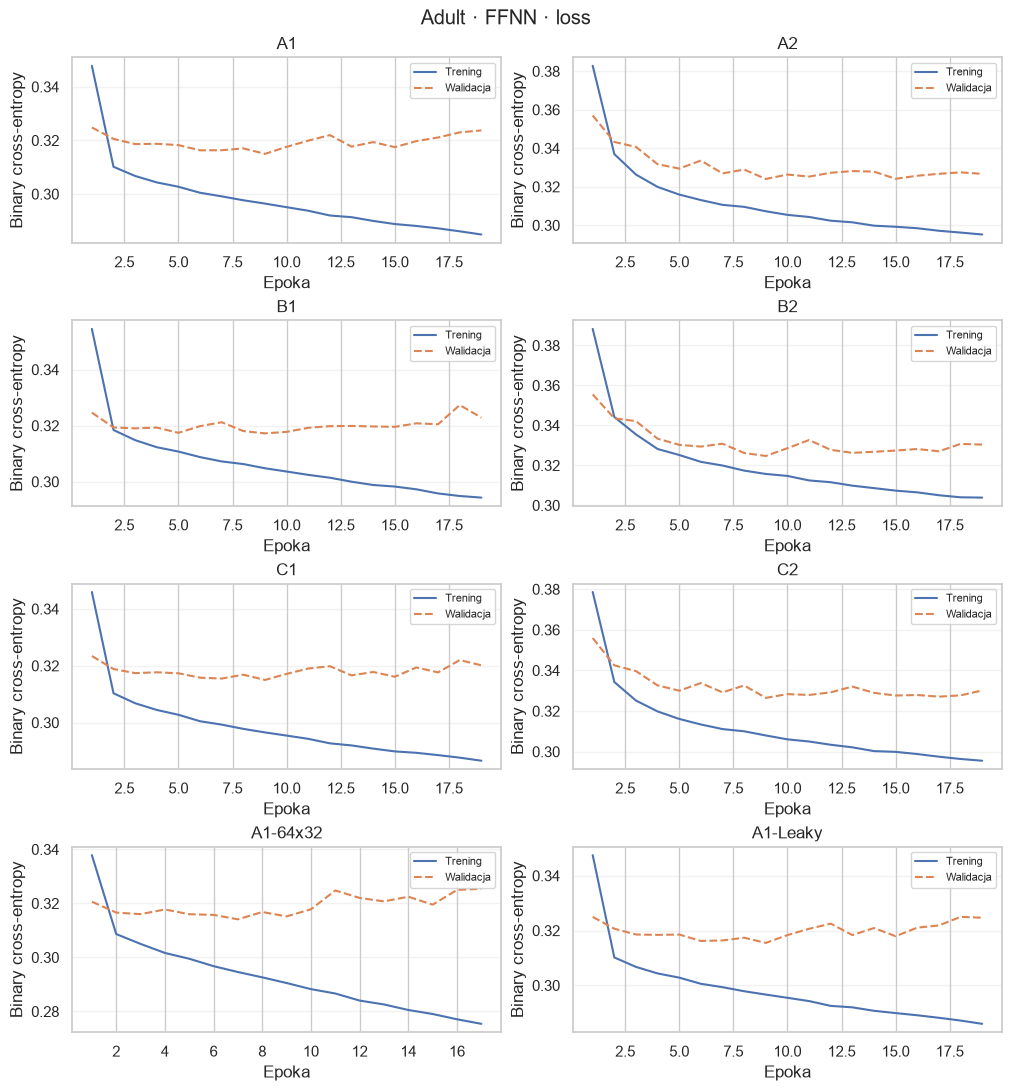

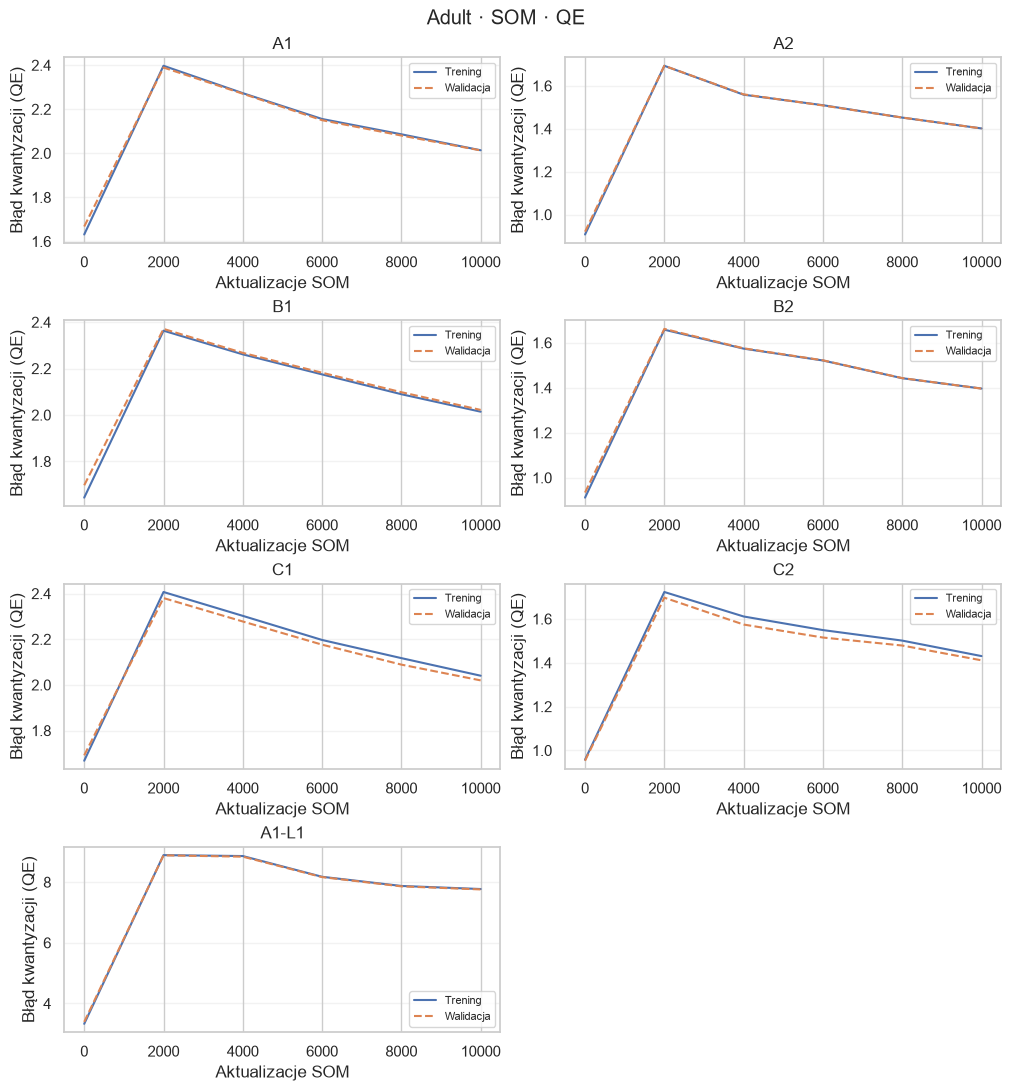

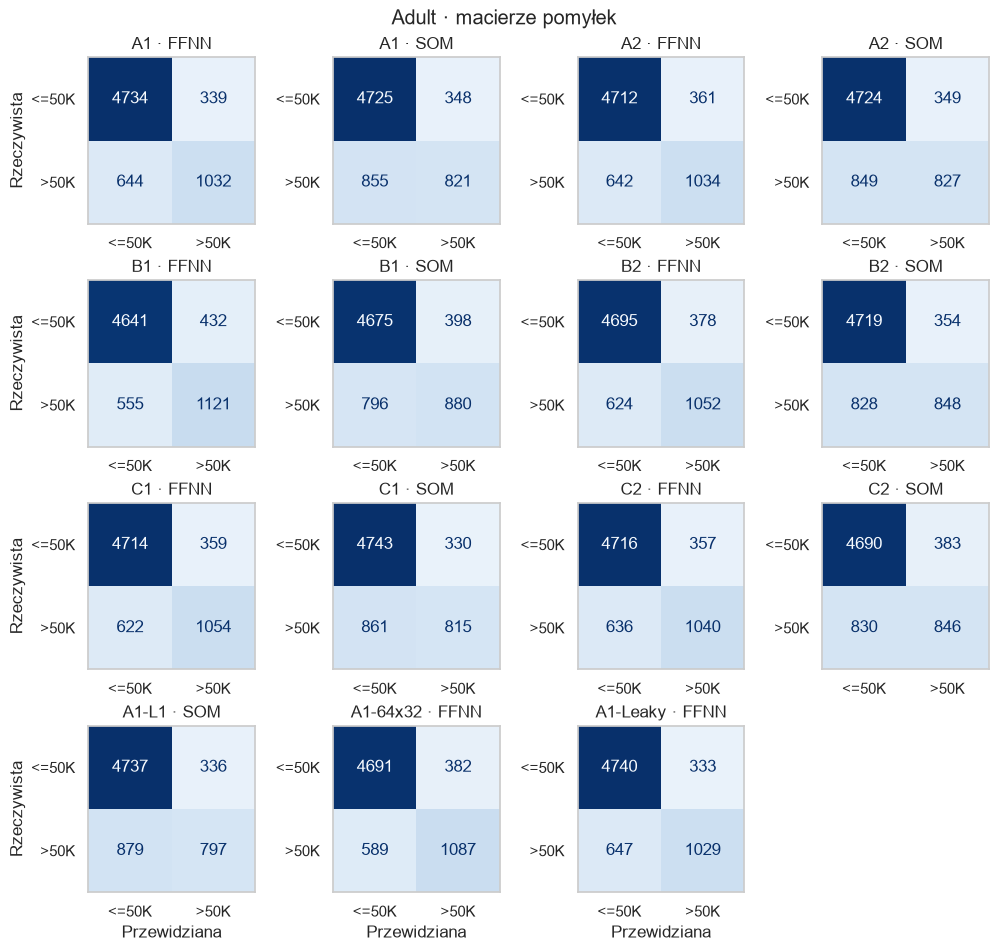

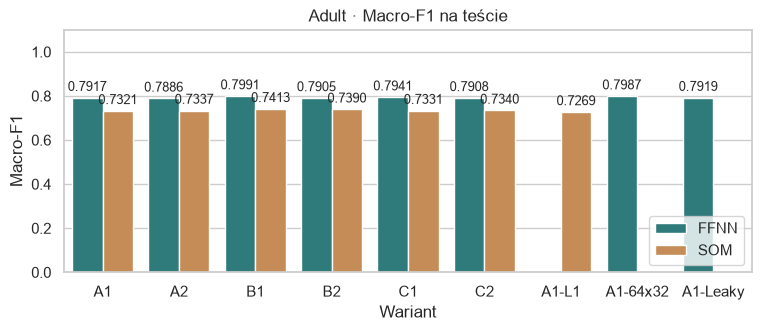

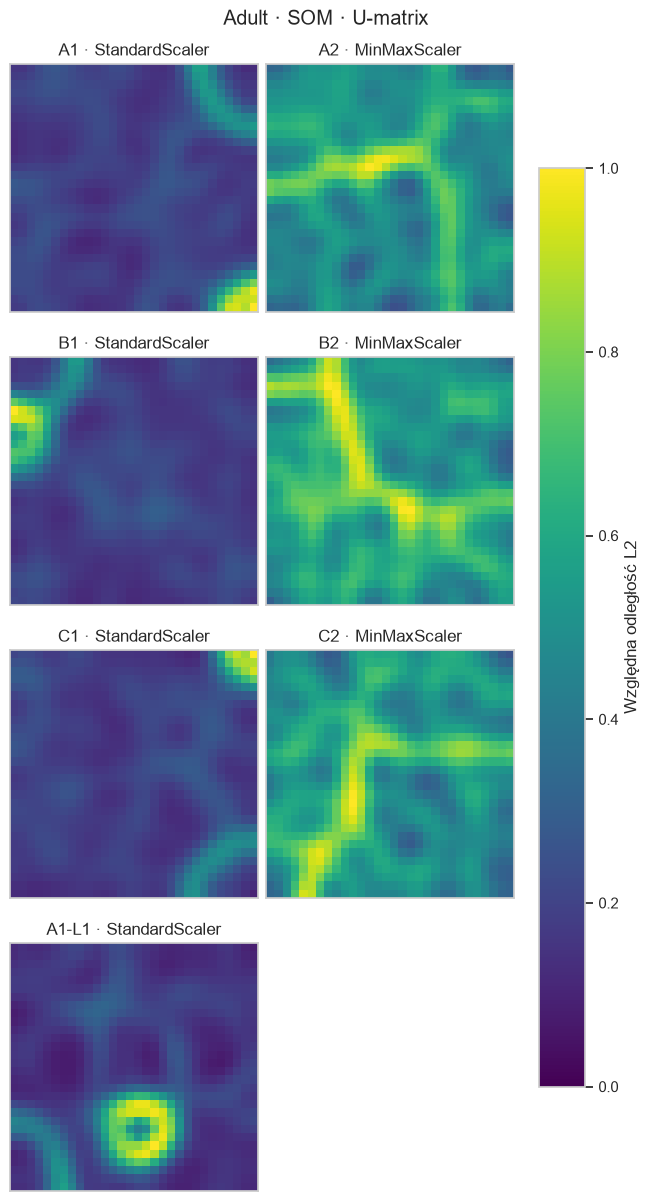

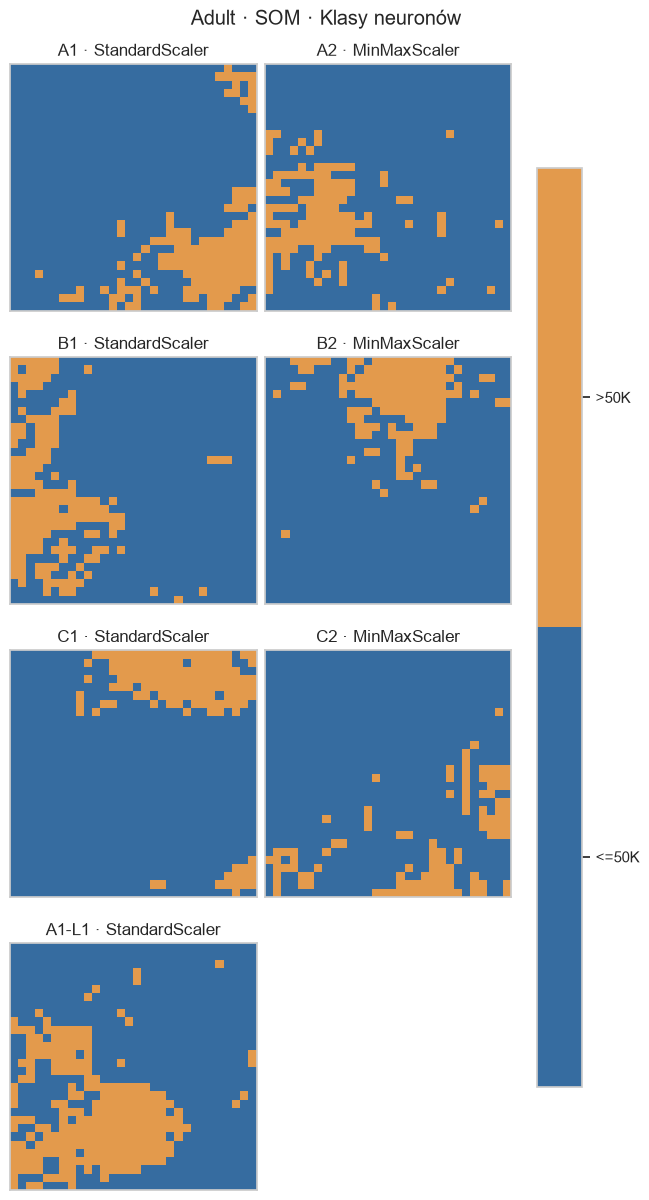

In [28]:
display(adult_results.round(4).replace({np.nan: '—'}))

plot_loss_curves(adult_loss_histories, 'Adult', 'FFNN')
plot_loss_curves(adult_loss_histories, 'Adult', 'SOM')

plot_confusion_matrices(adult_matrices, ['<=50K', '>50K'], 'Adult')

plot_macro_f1(adult_results, 'Adult')
plot_som_maps(adult_maps, ADULT_VARIANTS, 'Adult', ['<=50K', '>50K'])

**Struktura map Adult.** W A1 neurony z etykietą >50K skupiają się głównie przy prawej i dolnej krawędzi. W A2 większe skupisko jest po lewej, z pojedynczymi neuronami tej klasy także w innych częściach mapy. Jasne pasmo po prawej w U-matrix A2 przebiega również przez obszar <=50K. W tym obszarze sąsiednie neurony mogą się wyraźnie różnić mimo wspólnej etykiety.

### Banknote

In [29]:
bank_results, bank_maps, bank_matrices, bank_loss_histories = run_experiment(
    bank_splits, bank_y, BANK_NUMERIC, BANK_VARIANTS,
)

Trening  Test  Accuracy  Macro-recall  Macro-F1  \
Wariant Model                                                    
N1      FFNN       943   203    0.9901        0.9910    0.9901   
        SOM        943   203    0.9901        0.9910    0.9901   
N2      FFNN       943   203    0.9606        0.9593    0.9602   
        SOM        943   203    0.9951        0.9955    0.9950   
N1-L1   SOM        943   203    0.9901        0.9891    0.9900   
N1-2    FFNN       943   203    0.9901        0.9910    0.9901   

              Błąd kwantyzacji (QE) Błąd topograficzny  
Wariant Model                                           
N1      FFNN                      —                  —  
        SOM                  0.4174             0.0296  
N2      FFNN                      —                  —  
        SOM                  0.0829             0.0148  
N1-L1   SOM                  0.6784             0.0246  
N1-2    FFNN                      —                  —

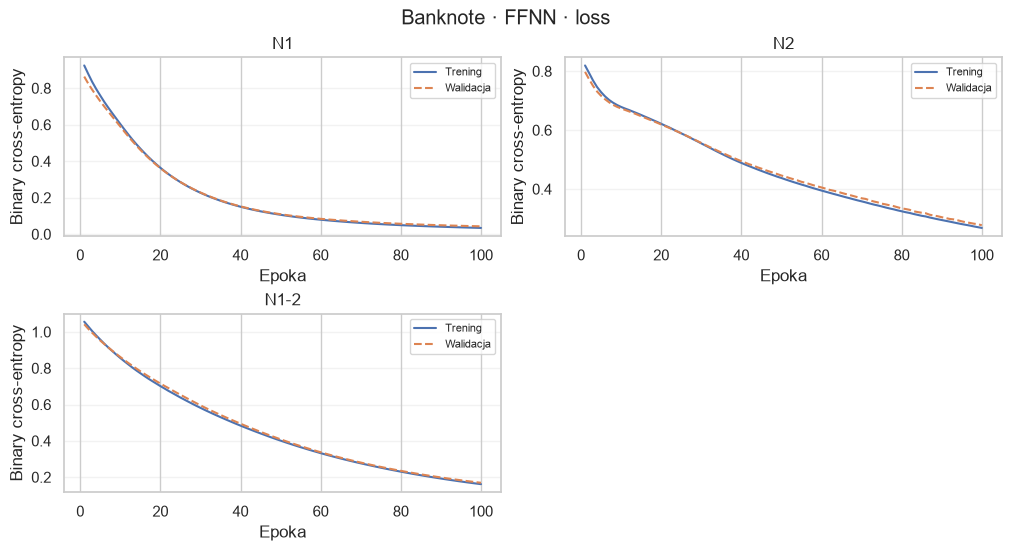

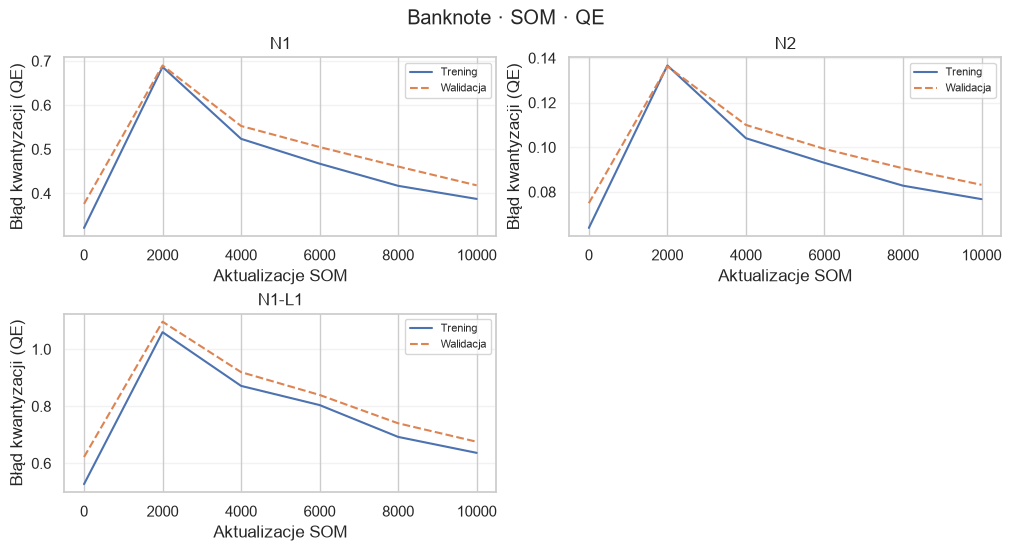

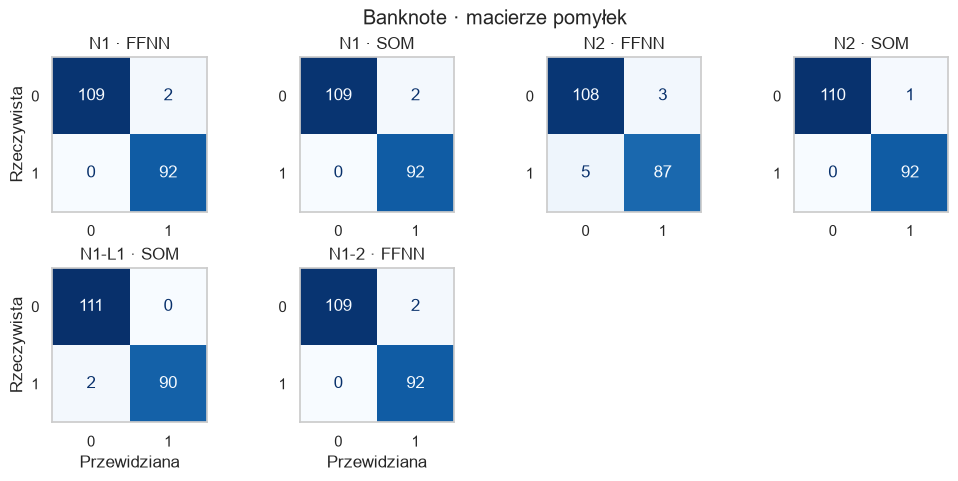

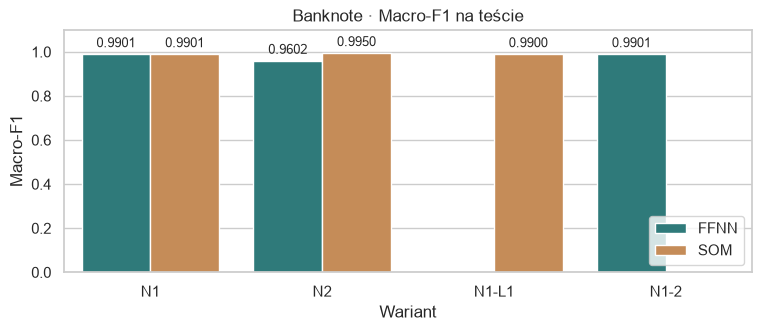

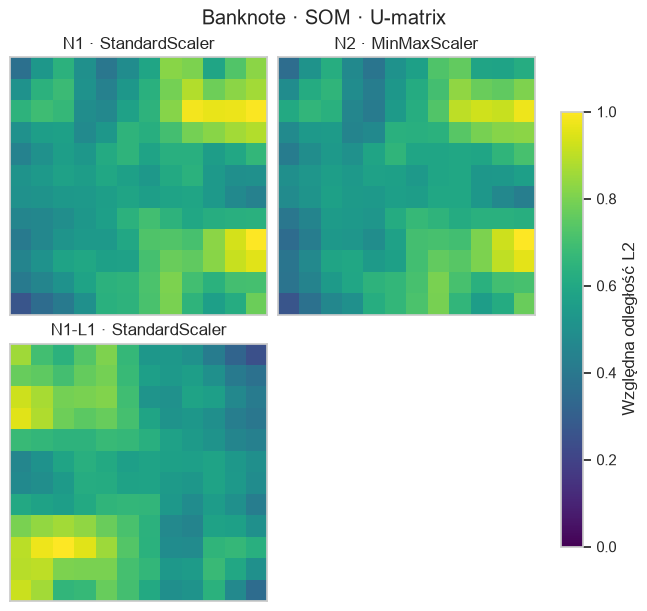

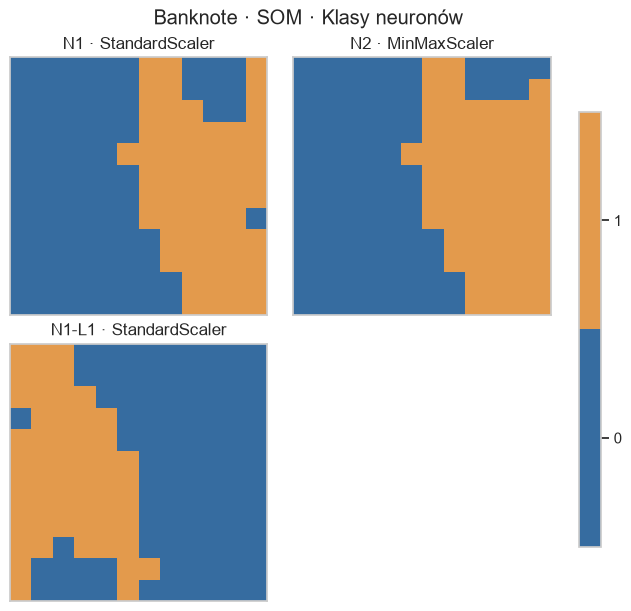

In [30]:
display(bank_results.drop(columns='F1 klasy >50K').round(4).replace({np.nan: '—'}))

plot_loss_curves(bank_loss_histories, 'Banknote', 'FFNN')
plot_loss_curves(bank_loss_histories, 'Banknote', 'SOM')

plot_confusion_matrices(bank_matrices, ['0', '1'], 'Banknote')

plot_macro_f1(bank_results, 'Banknote')
plot_som_maps(bank_maps, BANK_VARIANTS, 'Banknote', ['0', '1'])

**Struktura map Banknote.** W obu wariantach klasa 0 zajmuje głównie lewą część mapy, a klasa 1 prawą. Pojedynczemu polu klasy 0 przy prawej krawędzi N1 odpowiada w N2 pole klasy 1. Największe lokalne różnice między neuronami w U-matrix widać po prawej stronie obu map, również wewnątrz obszaru klasy 1. Na teście błąd topograficzny wyniósł 2,96% dla N1 i 1,48% dla N2.

## Wnioski i ograniczenia



### Odpowiedź na pytanie badawcze

Sposób przygotowania danych wpływa na FFNN i SOM, ale jego efekt zależy od zbioru i modelu - nie ma jednego ustawienia najlepszego w każdym przypadku.

- **Adult:** spośród wariantów obsługi braków najwyższe Macro-F1 uzyskał B1 (usunięcie niekompletnych wierszy i skalowanie używające `StandardScaler`). FFNN osiągnął **0,8004** wobec **0,7917** dla A1 (**+0,87 p.p.**), a SOM **0,7413** wobec **0,7321** (**+0,92 p.p.**).
- **Banknote:** zmiana skalowania na `MinMaxScaler` działała różnie dla modeli. Macro-F1 FFNN spadł z **0,9901** do **0,9602** (**−2,99 p.p.**), natomiast SOM wzrósł z **0,9901** do **0,9950** (**+0,50 p.p.**).


- **Zmiany konfiguracji modeli:**
  - Więcej neuronów w FFNN dla Adult (32x16 na 64x32) podniosło Macro-F1 z **0,7917** do **0,7987** (**+0,70 p.p.**). Dla Banknote zmniejszenie warstwy FFNN z 8 do 2 neuronów dało **0,9901** w obu wariantach (brak zmiany).
  - W SOM przejście z L2 (euklidesowej) na L1 (Manhattan) zmieniło Adult Macro-F1 z **0,7321** do **0,7269** (**−0,52 p.p.**) oraz błąd topograficzny z **2,62%** do **6,58%** (**+3,96 p.p.**). Dla Banknote Macro-F1 zmieniło się z **0,9901** do **0,9900** (**−0,01 p.p.**), a błąd topograficzny z **2,96%** do **2,46%** (**−0,50 p.p.**).
  - Aktywacja LeakyReLU zamiast ReLU w FFNN dla Adult zmieniła Macro-F1 z **0,7917** do **0,7919** (**+0,02 p.p.**); F1 klasy >50K pozostało **0,6774**.

W tym eksperymencie wybór strategii obsługi braków miał zauważalny wpływ na Adult, a wybór skalera na Banknote.


### Skrót wariantów

| Warianty | Co oznaczają |
| --- | --- |
| A1 / A2 | Adult: mediana i moda dla braków; standaryzacja / Min–Max |
| B1 / B2 | Adult: usunięcie niekompletnych rekordów treningowych; standaryzacja / Min–Max |
| C1 / C2 | Adult: `BRAK_DANYCH` dla kategorii, mediana i wskaźnik braku dla liczb; standaryzacja / Min–Max |
| N1 / N2 | Banknote: kompletne dane; standaryzacja / Min–Max |
| A1-L1 / N1-L1 | SOM: metryka Manhattan zamiast domyślnej euklidesowej, z preprocessingiem A1 / N1 |
| A1-64x32 | Adult FFNN: warstwy 64 i 32 neurony zamiast 32 i 16; preprocessing A1 |
| A1-Leaky | Adult FFNN: LeakyReLU zamiast ReLU; preprocessing A1 |
| N1-2 | Banknote FFNN: 2 neurony zamiast 8 w jednej warstwie; preprocessing N1 |


### Kiedy lepiej wybrać FFNN, a kiedy SOM?

- **FFNN wybierz przede wszystkim do klasyfikacji**, gdy celem jest przewidywanie etykiety. W Adult FFNN uzyskał wyższe Macro-F1 niż SOM: **0,7917 vs 0,7321** w A1 oraz **0,8004 vs 0,7413** w B1. FFNN uczy się bezpośrednio przewidywać klasę.
- **SOM wybierz do eksploracji i wizualizacji danych**, gdy ważne jest zobaczenie skupisk oraz relacji między obserwacjami na mapie. W Banknote oba modele osiągnęły **0,9901 Macro-F1** w N1; w N2 SOM uzyskał **0,9950**, a FFNN **0,9602**.
- **Nie ma jednego zwycięzcy dla wszystkich ustawień.** Wyniki Banknote pokazują, że wybór skalera może zmienić porównanie modeli.
